# Premier League Corner Analysis — 2015/16

Which teams score most from corners, which concede most, and **why**. Every
number here comes from StatsBomb's open event data for the full 2015/16 Premier
League season — 380 matches, 4,107 corners — linked to what happened next.

**A note on the season:** granular per-corner data (first contact, delivery,
landing zone) is licensed for the current season and costs thousands. 2015/16
is the complete Premier League season StatsBomb release free, so it's what lets
this analysis exist with real, checkable numbers rather than invented ones.

**Launch Jupyter from this project folder** so `from src import ...` resolves.

## 1. Setup

In [1]:
%pip install -q -r requirements.txt

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
from src import ingest, analyse
pd.set_option('display.max_columns', None)

## 2. Load the season
First run downloads 380 match files (a few minutes) and caches them; later runs
are instant.

In [3]:
corners = ingest.add_zones(ingest.fetch_season_corners())
print(f'{len(corners):,} corners')
corners.head()

4,107 corners


,match_id,attacking_team,defending_team,minute,end_x,end_y,delivery,first_contact,shot_taken,goal,distance_to_goal,zone
0,3754217,Arsenal,Chelsea,1,111.7,33.3,outswinger,attacker,True,False,10.666771,deeper / edge of area
1,3754217,Chelsea,Arsenal,17,112.8,53.6,inswinger,attacker,False,False,15.388307,deeper / edge of area
2,3754217,Chelsea,Arsenal,25,120.0,55.1,inswinger,none,False,False,15.100000,far post
3,3754217,Arsenal,Chelsea,42,109.1,39.8,outswinger,defender,False,False,10.901835,deeper / edge of area
4,3754217,Arsenal,Chelsea,49,113.8,45.8,inswinger,defender,False,False,8.489994,deeper / edge of area


## 3. Who scores most from corners?

In [4]:
att = analyse.attacking_summary(corners)
att[['team','corners','first_contact_pct','shot_rate','goals','goal_rate']].head(10)

,team,corners,first_contact_pct,shot_rate,goals,goal_rate
0,Manchester City,257,0.704,0.444,11,0.0428
1,Crystal Palace,219,0.667,0.420,11,0.0502
2,Tottenham Hotspur,254,0.598,0.362,10,0.0394
3,Liverpool,266,0.650,0.365,10,0.0376
4,Southampton,220,0.636,0.382,9,0.0409
5,West Bromwich Albion,188,0.489,0.298,9,0.0479
6,Norwich City,188,0.590,0.388,9,0.0479
7,AFC Bournemouth,221,0.665,0.312,9,0.0407
8,West Ham United,224,0.679,0.397,8,0.0357
9,Everton,218,0.596,0.362,8,0.0367


## 4. Who concedes most from corners?

In [5]:
dfn = analyse.defending_summary(corners)
dfn[['team','corners_faced','defensive_contact_pct','goals_conceded','concede_rate']].head(10)

,team,corners_faced,defensive_contact_pct,goals_conceded,concede_rate
0,Swansea City,197,0.239,13,0.0660
1,Liverpool,175,0.331,12,0.0686
2,Everton,229,0.249,11,0.0480
3,Stoke City,241,0.290,11,0.0456
4,Aston Villa,233,0.193,9,0.0386
5,AFC Bournemouth,169,0.314,9,0.0533
6,Newcastle United,242,0.277,8,0.0331
7,Southampton,198,0.374,7,0.0354
8,Sunderland,223,0.215,7,0.0314
9,Leicester City,238,0.282,7,0.0294


## 5. First contact — the mechanism
At the level of an individual corner, who touches the ball first is decisive.

In [6]:
analyse.contact_breakdown(corners)

,first_contact,corners,shot_rate,goal_rate
0,attacker,2614,0.4682,0.0482
1,defender,1157,0.2040,0.0147
2,none,336,0.0000,0.0000


## 6. Delivery type and landing zone

In [7]:
analyse.delivery_breakdown(corners)

,delivery,corners,first_contact_pct,shot_rate,goal_rate
0,inswinger,1625,0.5052,0.3157,0.0375
1,low/short,670,0.9881,0.3119,0.0343
2,outswinger,1409,0.6125,0.4074,0.0334
3,straight,403,0.6650,0.4069,0.0298


In [8]:
analyse.zone_breakdown(corners)

,zone,corners,shots,goals,shot_rate,goal_rate,shot_rate_low,shot_rate_high
0,deeper / edge of area,2503,1024,87,0.409,0.0348,0.390,0.428
1,near post,519,147,25,0.283,0.0482,0.246,0.323
2,far post,527,148,14,0.281,0.0266,0.244,0.321
3,central six-yard,558,141,17,0.253,0.0305,0.218,0.290


## 7. The 'why' — and a surprise
Naively you'd expect the teams that win first contact most often to score most.
Across the 20 teams, they don't: the correlation is weak and slightly negative.
Winning first contact matters *per corner*, but at team-season level, **how many
corners you take and the quality of contact matters more than the raw win
rate**. Reporting this honestly, rather than forcing a clean story, is the
point.

In [9]:
corr = analyse.contact_vs_outcome_correlation(att, dfn)
print('Attack: first-contact% vs goal-rate   r =', corr['attack_contact_vs_goal_rate_r'])
print('Defend: def-contact% vs concede-rate  r =', corr['defend_contact_vs_concede_rate_r'])

Attack: first-contact% vs goal-rate   r = -0.229
Defend: def-contact% vs concede-rate  r = -0.011


## 8. Net corner battle — scored minus conceded

In [10]:
net = analyse.net_set_piece_table(att, dfn)
net

,team,goals,corners,goals_conceded,corners_faced,net_corner_goals
0,Crystal Palace,11,219,3,219,8
1,Manchester City,11,257,7,164,4
2,Tottenham Hotspur,10,254,6,182,4
3,West Bromwich Albion,9,188,5,222,4
4,Norwich City,9,188,5,202,4
5,Arsenal,7,227,4,181,3
6,West Ham United,8,224,6,196,2
7,Southampton,9,220,7,198,2
8,Manchester United,4,228,2,143,2
9,Chelsea,7,239,6,209,1


## 9. All the charts

In [11]:
from src import main as pipeline
from pathlib import Path
out = Path('outputs'); out.mkdir(exist_ok=True)
pipeline.plot_attacking(att, out/'attacking.png')
pipeline.plot_defending(dfn, out/'defending.png')
pipeline.plot_first_contact(analyse.contact_breakdown(corners), out/'first_contact.png')
pipeline.plot_why_scatter(corr, out/'why_scatter.png')
pipeline.plot_net(net, out/'net_corner_goals.png')
print('charts written')

charts written


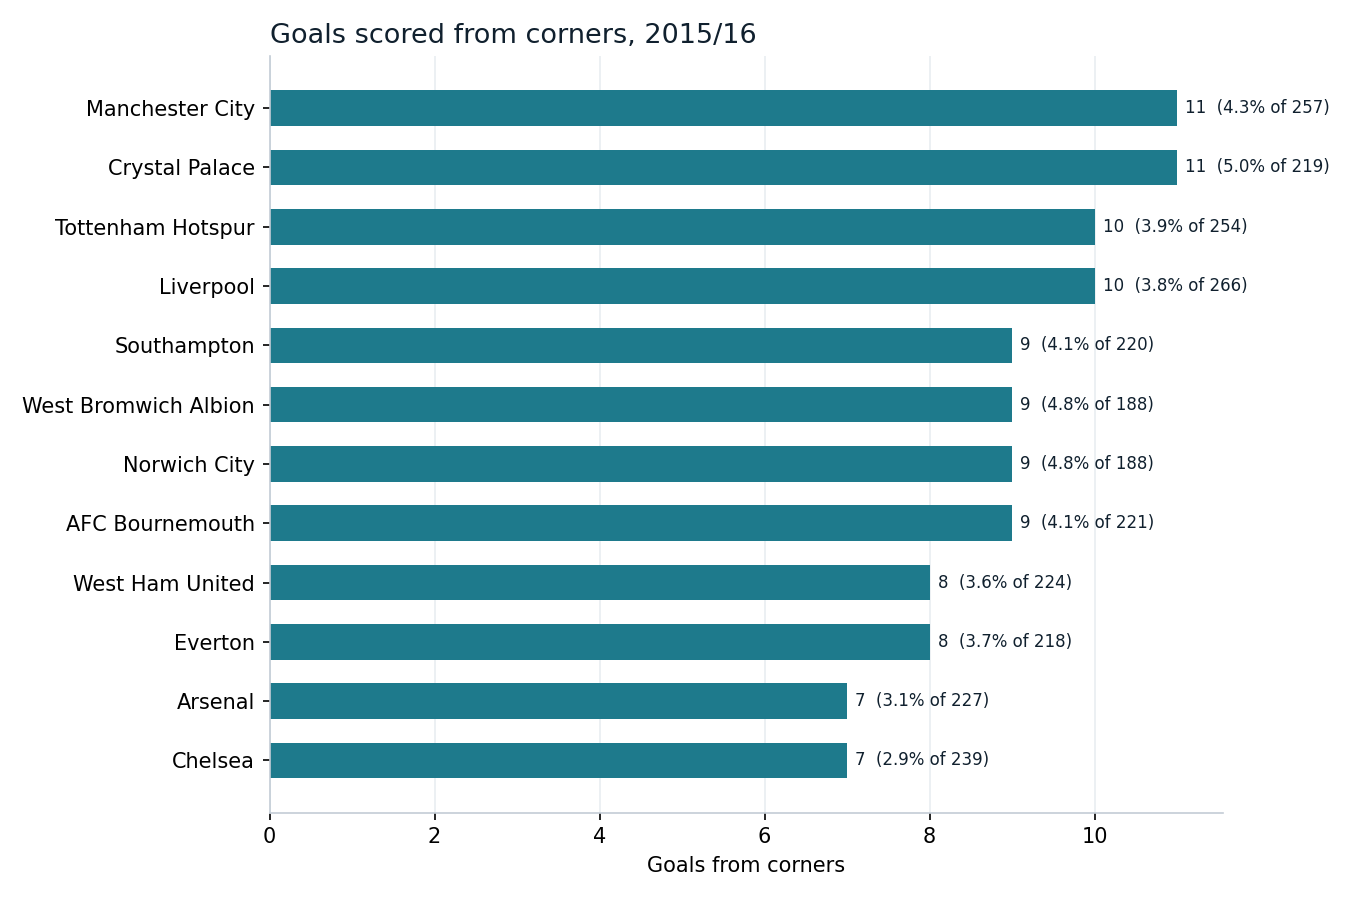

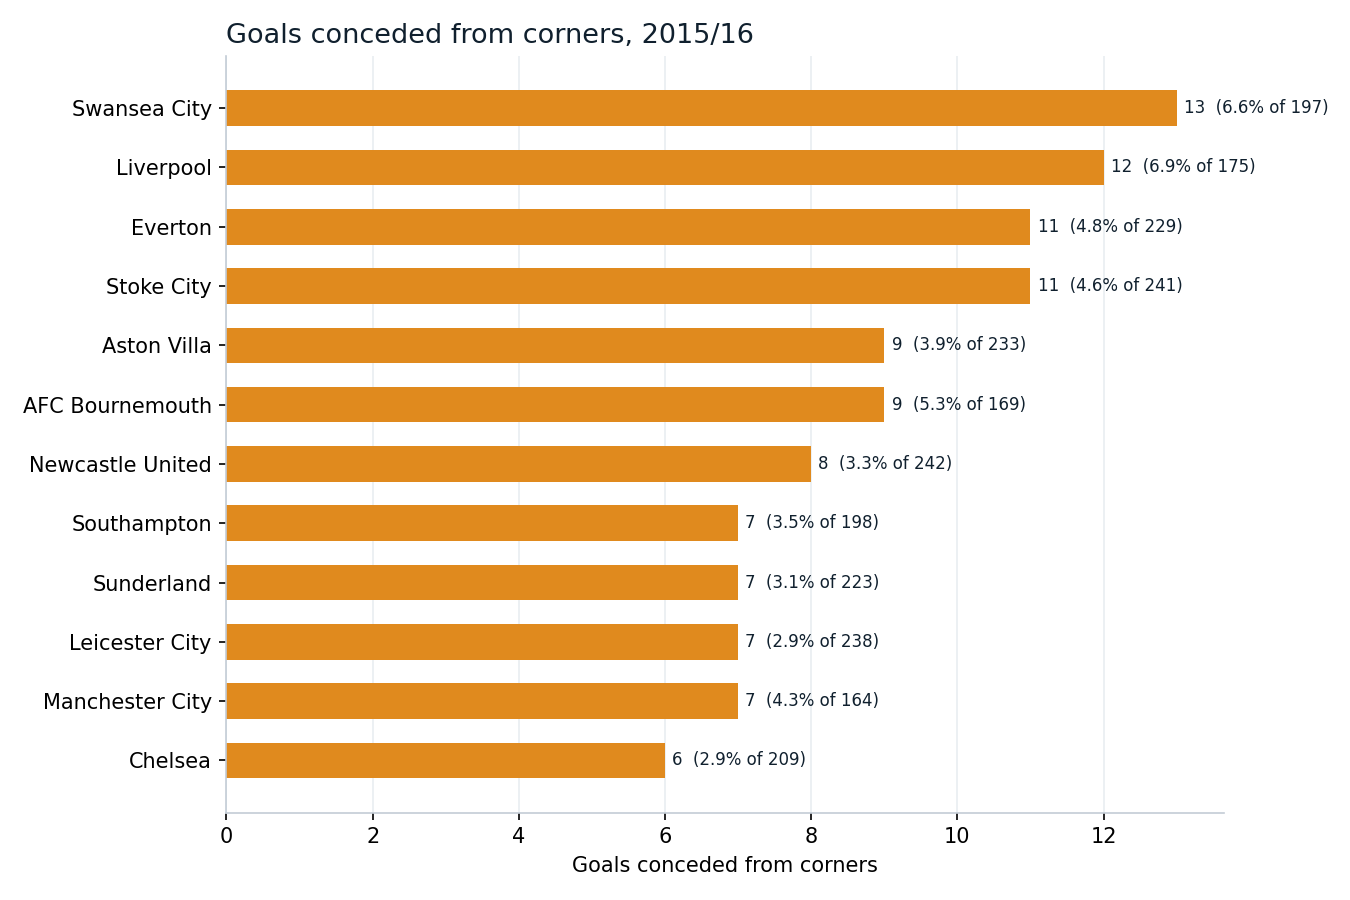

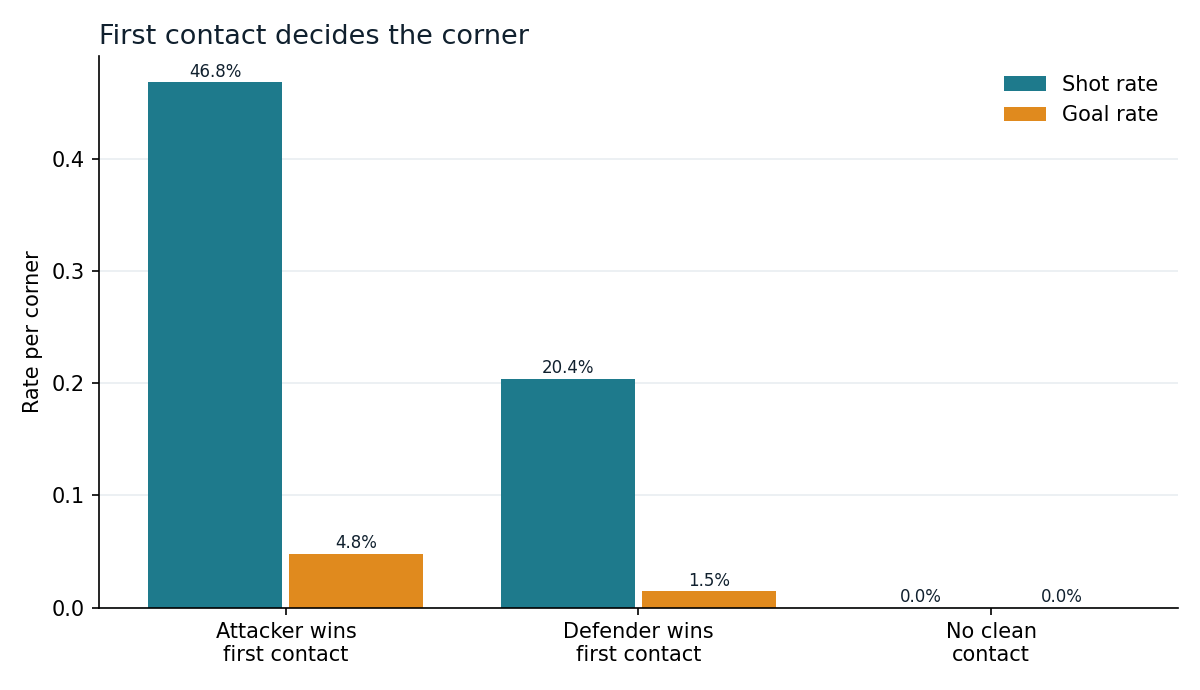

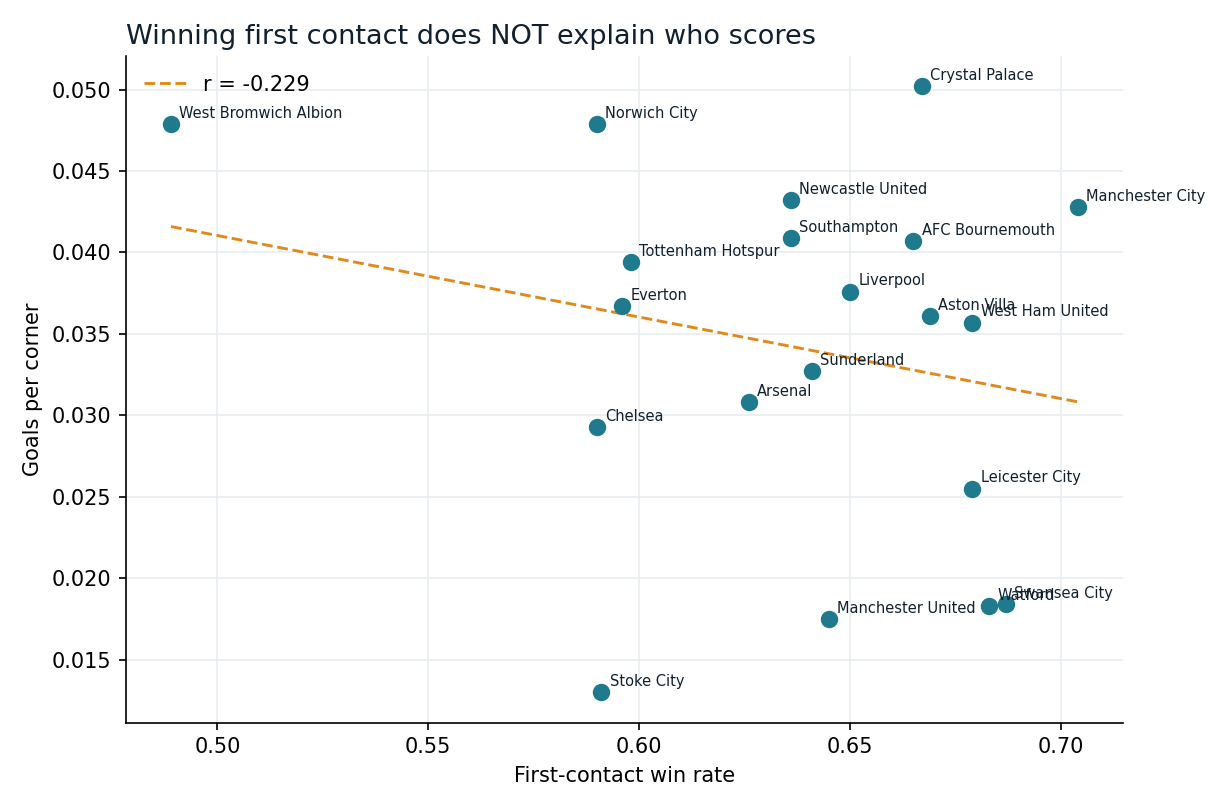

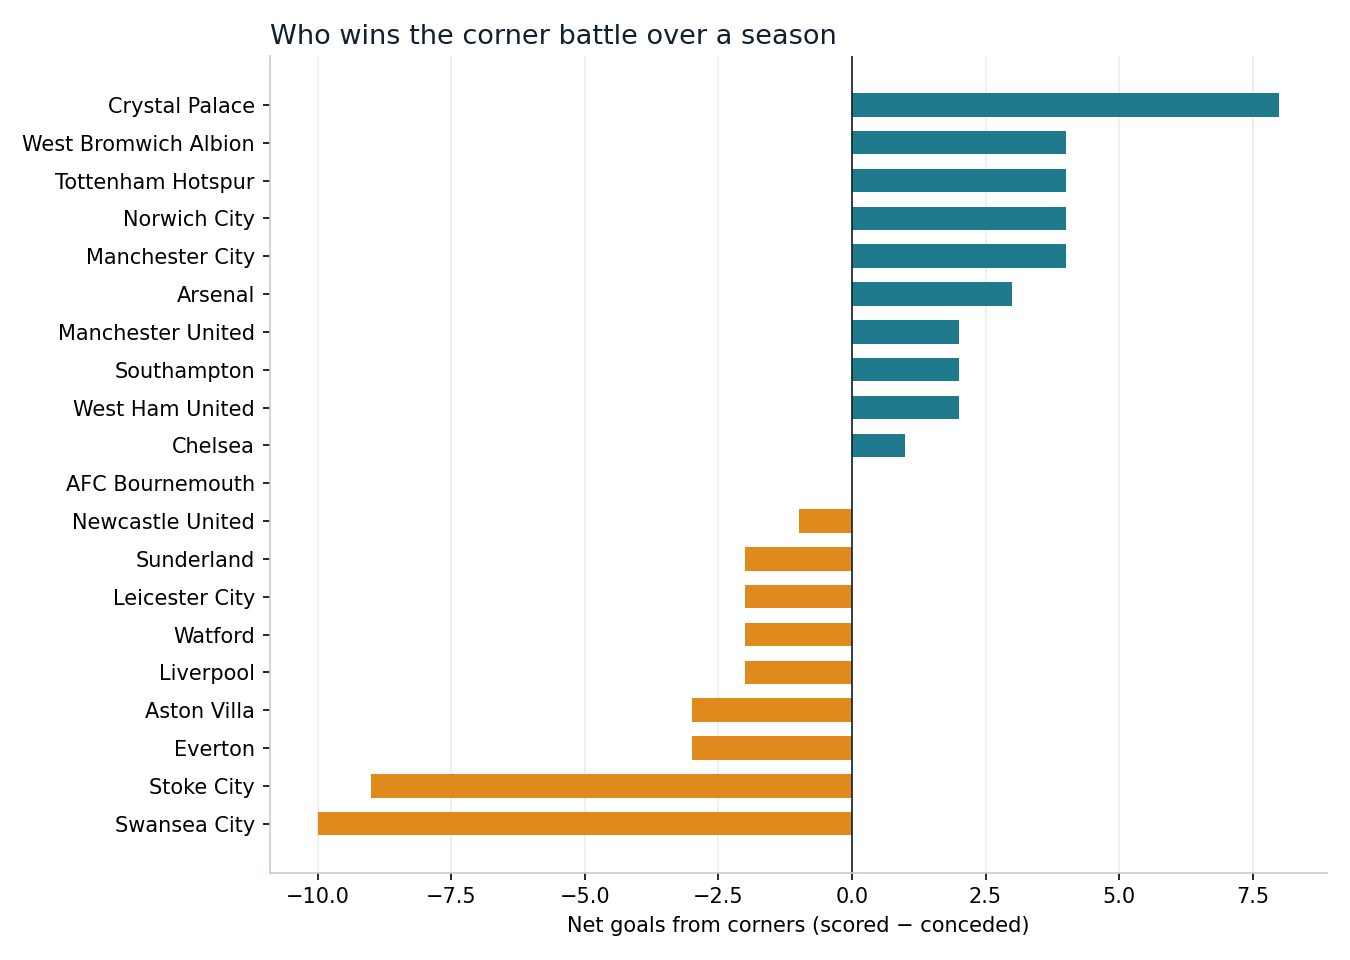

In [12]:
from IPython.display import Image, display
for n in ['attacking.png','defending.png','first_contact.png','why_scatter.png','net_corner_goals.png']:
    display(Image(filename=f'outputs/{n}'))

## 10. Tests

In [13]:
!python -m pytest tests/ -q

.

...

...                                                                  [100%]
7 passed in 0.82s
